# Lekcja 7. Splątanie i stan Bella

**Cel:** zbudować stan Bella krok po kroku na macierzach i zrozumieć, czym splątanie różni się od superpozycji i od zwykłej klasycznej korelacji.

## 1. Definicja

Stan $v \in \mathbb{C}^2 \otimes \mathbb{C}^2$ jest **produktowy**, jeśli $v = a \otimes b$ dla pewnych $a, b \in \mathbb{C}^2$. W przeciwnym razie jest **splątany**.

**Kryterium dla dwóch kubitów:** ułóż współrzędne $v = (v_{00}, v_{01}, v_{10}, v_{11})$ w macierz

$$M = \begin{pmatrix} v_{00} & v_{01}\\ v_{10} & v_{11}\end{pmatrix}.$$

Stan jest produktowy wtedy i tylko wtedy, gdy $\operatorname{rank} M = 1$, czyli $\det M = v_{00}v_{11} - v_{01}v_{10} = 0$. Dla $a \otimes b$ mamy $M = ab^{T}$, macierz rzędu 1. (Ogólnie: rozkład Schmidta to SVD macierzy $M$, a rząd to rząd Schmidta.) Prosty wyznacznik działa tylko dla dwóch kubitów.

Splątanie **nie jest nowym aksjomatem**: wynika z iloczynu tensorowego i reguły Borna. Ale nie jest też wyjątkiem: stany produktowe to „cienki” podzbiór, a losowy stan wielu kubitów jest prawie na pewno splątany.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

np.set_printoptions(precision=3, suppress=True)
GREEN, DARK, LIGHT, GREY, ORANGE = "#44B749", "#1A8A1F", "#96E199", "#8A8A8A", "#E08A00"

e0 = np.array([1, 0], dtype=complex)   # etykieta |0⟩
e1 = np.array([0, 1], dtype=complex)   # etykieta |1⟩

def norm(v):
    return np.sqrt(np.sum(np.abs(v) ** 2))

def show(v, n=None):
    """Wypisz wektor stanu z etykietami bitów (etykieta = pozycja w zapisie dwójkowym)."""
    v = np.asarray(v)
    n = n or int(np.log2(len(v)))
    for k, a in enumerate(v):
        if abs(a) > 1e-12:
            print(f"  pozycja {k} ({format(k, f'0{n}b')}): amplituda {np.round(a, 3)}, P = {abs(a)**2:.3f}")

from functools import reduce
kron = lambda *ms: reduce(np.kron, ms)
I2 = np.eye(2)
H = np.array([[1, 1], [1, -1]]) / np.sqrt(2)
CNOT = np.array([[1, 0, 0, 0],
                 [0, 1, 0, 0],
                 [0, 0, 0, 1],
                 [0, 0, 1, 0]])

def det_test(v):
    return v[0] * v[3] - v[1] * v[2]

s = 1 / np.sqrt(2)
przyklady = {
    "(1,0,0,0)      |00⟩":        [1, 0, 0, 0],
    "(1,1,0,0)/√2   |0⟩⊗|+⟩":     [s, s, 0, 0],
    "(1,1,1,1)/2    |+⟩⊗|+⟩":     [.5, .5, .5, .5],
    "(1,-1,1,-1)/2  |+⟩⊗|−⟩":     [.5, -.5, .5, -.5],
    "(1,i,0,0)/√2   |0⟩⊗|+i⟩":    [s, 1j * s, 0, 0],
    "(1,0,0,1)/√2   Bell Φ+":     [s, 0, 0, s],
    "(0,1,1,0)/√2   Bell Ψ+":     [0, s, s, 0],
    "(3,0,0,4)/5":                [.6, 0, 0, .8],
    "(1,1,1,-1)/2":               [.5, .5, .5, -.5],
}
for nazwa, v in przyklady.items():
    d = det_test(np.array(v, dtype=complex))
    print(f"{nazwa:>26}:  det = {np.round(np.real_if_close(d), 3):>6}   ->  {'splątany' if abs(d) > 1e-12 else 'produktowy'}")

       (1,0,0,0)      |00⟩:  det =    0.0   ->  produktowy
    (1,1,0,0)/√2   |0⟩⊗|+⟩:  det =    0.0   ->  produktowy
    (1,1,1,1)/2    |+⟩⊗|+⟩:  det =    0.0   ->  produktowy
    (1,-1,1,-1)/2  |+⟩⊗|−⟩:  det =    0.0   ->  produktowy
   (1,i,0,0)/√2   |0⟩⊗|+i⟩:  det =    0.0   ->  produktowy
    (1,0,0,1)/√2   Bell Φ+:  det =    0.5   ->  splątany
    (0,1,1,0)/√2   Bell Ψ+:  det =   -0.5   ->  splątany
               (3,0,0,4)/5:  det =   0.48   ->  splątany
              (1,1,1,-1)/2:  det =   -0.5   ->  splątany

Zwróć uwagę na dwie ostatnie pary:

- $(1, 1, 1, 1)/2$: wszystkie współrzędne niezerowe, a stan jest **produktowy** ($u_+ \otimes u_+$);
- $(1, 1, 1, -1)/2$: różni się **jednym znakiem**, a jest **splątany**.

O splątaniu decydują relacje między współrzędnymi, a nie to, ile ich jest niezerowych.

| | superpozycja? | splątany? |
|---|---|---|
| $e_1 = \lvert 01\rangle$ | nie | nie |
| $u_+ \otimes e_0$ | tak | nie |
| stan Bella | tak | tak |

W bazie obliczeniowej (i w każdej bazie produktowej) splątanie wymaga superpozycji (takie wektory bazowe są zawsze produktowe), ale superpozycja nie wymaga splątania.

## 2. Stan Bella krok po kroku

Obwód: $H$ na kubicie 0, potem CNOT (kubit 0 kontrolny, kubit 1 docelowy).

**Krok 0.** $v_0 = e_0 \otimes e_0 = (1, 0, 0, 0)$, etykieta $|00\rangle$.

**Krok 1.** „$H$ na kubicie 0” w $\mathbb{C}^4$ to $H \otimes I$ (każdy element $H$ mnoży cały blok $I$):

$$H \otimes I = \frac{1}{\sqrt2}\begin{pmatrix}1&0&1&0\\0&1&0&1\\1&0&-1&0\\0&1&0&-1\end{pmatrix}, \qquad v_1 = (H \otimes I)v_0 = \tfrac{1}{\sqrt2}(1, 0, 1, 0).$$

To **nadal stan produktowy**: $v_1 = u_+ \otimes e_0$. Jest superpozycja, nie ma splątania.

**Krok 2.** CNOT to macierz permutacji: zostawia pozycje 0 i 1, zamienia pozycje 2 i 3 (jeśli pierwszy bit to 1, odwróć drugi):

$$v_2 = \mathrm{CNOT}\, v_1 = \tfrac{1}{\sqrt2}(1, 0, 0, 1) = \tfrac{1}{\sqrt2}(e_0 + e_3).$$

To stan Bella $\Phi^+$ (etykiety $(|00\rangle + |11\rangle)/\sqrt2$). Macierz $M = \tfrac{1}{\sqrt2}I$ ma rząd 2, więc stan jest splątany.

**Cały obwód:** $U = \mathrm{CNOT}\,(H \otimes I)$ (kolejność od prawej). Pierwsza kolumna $U$ to dokładnie $v_2$.

CNOT **nie** jest iloczynem tensorowym $A \otimes B$ dwóch bramek jednokubitowych: działa na kubit 1 w zależności od stanu kubitu 0. Dlatego potrafi przeprowadzić stan produktowy w splątany, czego żadna bramka $A \otimes B$ nie zrobi.

krok 0: [1. 0. 0. 0.]   det = 0.000
krok 1: [0.707 0.    0.707 0.   ]   det = 0.000
krok 2: [0.707 0.    0.    0.707]   det = 0.500

cała macierz obwodu U = CNOT·(H⊗I):
 [[ 0.707  0.     0.707  0.   ]
 [ 0.     0.707  0.     0.707]
 [ 0.     0.707  0.    -0.707]
 [ 0.707  0.    -0.707  0.   ]]

reguła Borna dla v2:
  pozycja 0 (00): amplituda (0.707+0j), P = 0.500
  pozycja 3 (11): amplituda (0.707+0j), P = 0.500

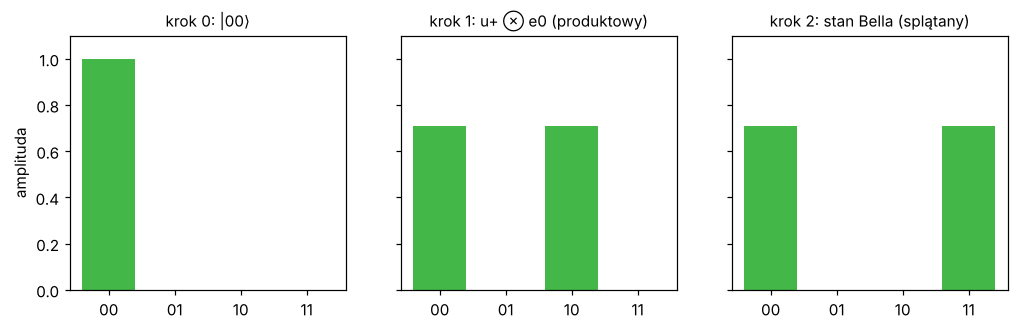

In [2]:
v0 = kron(e0, e0)
v1 = kron(H, I2) @ v0
v2 = CNOT @ v1
U = CNOT @ kron(H, I2)

for k, v in enumerate((v0, v1, v2)):
    print(f"krok {k}: {np.round(v.real, 3)}   det = {det_test(v).real:.3f}")
print("\ncała macierz obwodu U = CNOT·(H⊗I):\n", np.round(U, 3))
print("\nreguła Borna dla v2:"); show(v2)

fig, axs = plt.subplots(1, 3, figsize=(11, 3), sharey=True)
for ax, v, t in zip(axs, (v0, v1, v2), ("krok 0: |00⟩", "krok 1: u+ ⊗ e0 (produktowy)", "krok 2: stan Bella (splątany)")):
    ax.bar(["00", "01", "10", "11"], v.real, color=[GREEN if a else "#EEE" for a in v.real])
    ax.set_title(t, fontsize=10); ax.set_ylim(0, 1.1)
axs[0].set_ylabel("amplituda")

## 3. Co splątanie znaczy fizycznie

**Części nie mają własnych stanów.** Całość jest w pełni określona, a ani bit informacji nie siedzi w kubitach osobno. Pomiar **tylko** kubitu 0, w dowolnej bazie, daje zawsze 50/50. Dla pojedynczego kubitu w czystym stanie zawsze istnieje baza z pewnym wynikiem; dla kubitu wyjętego ze stanu Bella nie ma takiej bazy (na sferze Blocha to środek kuli).

**Pomiar jednego kubitu ustala drugi.** Wynik 0 na kubicie 0 (prawdopodobieństwo 1/2) zostawia pozycje z pierwszym bitem 0, po normalizacji $e_0 = |00\rangle$, więc kubit 1 jest na pewno w 0. Wynik 1 daje $e_3 = |11\rangle$.

**Czym to się różni od dwóch kopert z tą samą losową kartką?** Koperty też dają idealną korelację w jednej bazie. Różnica wychodzi w innej bazie: $(H \otimes H)v_2 = v_2$, czyli w bazie $x$ stan Bella wygląda tak samo, wyniki dalej zawsze się zgadzają (++ albo −−). Klasyczne koperty w bazie $x$ dają dwa niezależne rzuty monetą. Dla $\Phi^+$ wyniki są idealnie zgodne w bazach $z$ i $x$ (a w bazie $y$ idealnie przeciwne: $(Y \otimes Y)v_2 = -v_2$). To już wyklucza prosty model kopert, ale jeszcze nie każdy model z ukrytymi zmiennymi: można wyobrazić sobie dwie kartki w kopercie, jedną na bazę $z$, drugą na $x$ (to był argument EPR). Wszystkie takie modele wyklucza dopiero test Bella poniżej.

Przy pomiarach pod różnymi kątami nierówność Bella (CHSH) pokazuje, że żaden model z ukrytymi „kartkami w kopertach” nie da statystyk stanu Bella, a eksperymenty potwierdzają mechanikę kwantową (testy bez luk z 2015 r.: Hensen i in., Giustina i in., Shalm i in.; Nagroda Nobla 2022). Histogram 00/11 z jednej bazy (jak na slajdzie 6 z ibm_fez) sam w sobie tego nie dowodzi.

**Czego splątanie nie robi:** nie przesyła informacji. Osoba z samym kubitem 1 zawsze widzi 50/50, niezależnie od tego, co zrobiono z kubitem 0. Korelację widać dopiero po porównaniu wyników zwykłym kanałem.

In [3]:
print("(H⊗H)·v2 =", np.round(kron(H, H) @ v2, 3), " -> ten sam wektor")
Y = np.array([[0, -1j], [1j, 0]])
print("(Y⊗Y)·v2 =", np.round(kron(Y, Y) @ v2, 3), " -> minus ten sam wektor: w bazie y wyniki zawsze przeciwne")

rng = np.random.default_rng(3)
N = 10_000

def shoty(v, baza_x):
    w = kron(H, H) @ v if baza_x else v            # pomiar w bazie x = najpierw H⊗H
    k = rng.choice(4, size=N, p=np.abs(w) ** 2)
    a, b = k // 2, k % 2
    return np.mean(a == b)

# klasyczne koperty: z prawdopodobieństwem 1/2 obie "0" (e0⊗e0), z 1/2 obie "1" (e1⊗e1)
def koperty(baza_x):
    zgodne = 0
    for _ in range(N // 10):
        v = kron(e0, e0) if rng.random() < 0.5 else kron(e1, e1)
        w = kron(H, H) @ v if baza_x else v
        k = rng.choice(4, p=np.abs(w) ** 2)
        zgodne += (k // 2 == k % 2)
    return zgodne / (N // 10)

for baza_x, nazwa in ((False, "baza z"), (True, "baza x")):
    print(f"{nazwa}: stan Bella -> wyniki zgodne w {shoty(v2, baza_x):.0%},  koperty -> {koperty(baza_x):.0%}")

(H⊗H)·v2 = [0.707+0.j 0.   +0.j 0.   +0.j 0.707+0.j]  -> ten sam wektor
(Y⊗Y)·v2 = [-0.707+0.j  0.   +0.j  0.   +0.j -0.707+0.j]  -> minus ten sam wektor: w bazie y wyniki zawsze przeciwne
baza z: stan Bella -> wyniki zgodne w 100%,  koperty -> 100%
baza x: stan Bella -> wyniki zgodne w 100%,  koperty -> 53%

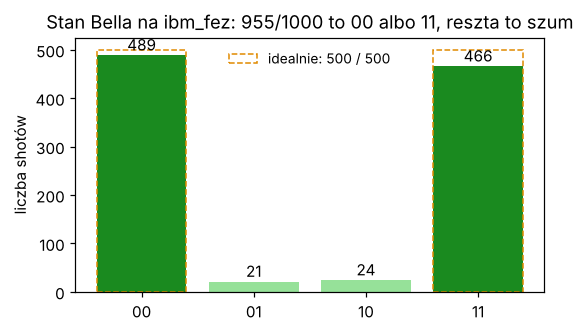

In [4]:
# Ten sam stan na prawdziwym sprzęcie: ibm_fez, 1000 shotów (slajd 6 prezentacji)
ibm = {"00": 489, "01": 21, "10": 24, "11": 466}
fig, ax = plt.subplots(figsize=(5.5, 3))
ax.bar(ibm.keys(), ibm.values(), color=[DARK, LIGHT, LIGHT, DARK])
ax.bar(["00", "11"], [500, 500], fill=False, edgecolor=ORANGE, ls="--", label="idealnie: 500 / 500")
for k, n in ibm.items():
    ax.text(k, n + 10, n, ha="center")
ax.set_ylabel("liczba shotów"); ax.legend(frameon=False, fontsize=9)
ax.set_title("Stan Bella na ibm_fez: 955/1000 to 00 albo 11, reszta to szum")

## 4. Splątanie jako zasób

- Obwody bez splątania da się wydajnie symulować klasycznie: każdy kubit to osobny wektor w $\mathbb{C}^2$, pamięć rośnie liniowo. Do wykładniczego kosztu symulacji (16 PiB dla 50 kubitów) splątanie jest konieczne, ale nie wystarcza: obwody Clifforda tworzą silnie splątane stany, a mimo to da się je wydajnie symulować (twierdzenie Gottesmana–Knilla).
- Teleportacja, kryptografia kwantowa oparta na splątaniu (E91; BB84 go nie potrzebuje) i korekcja błędów opierają się na splątaniu.
- Splątanie da się mierzyć (rząd Schmidta, entropia splątania): to cała osobna teoria.

## Podsumowanie

> Splątanie to nie nowa reguła, tylko nazwa dla wektorów, które nie są iloczynami tensorowymi; dla dwóch kubitów test to $\det M \ne 0$. Stan całości jest w pełni określony, ale części nie mają własnych stanów, a cała informacja siedzi w korelacjach, których nie da się odtworzyć żadnym lokalnym modelem klasycznym (Bell, CHSH). Tworzą je dopiero bramki wielokubitowe, takie jak CNOT.

## Zadania

1. Policz $H \otimes I$ ręcznie i sprawdź krok 1.
2. Co wyjdzie z obwodu (H, potem CNOT), jeśli zaczniesz od $e_1 = |01\rangle$? Czy wynik jest splątany? (Cztery wejścia $e_0, \dots, e_3$ dają cztery stany Bella: bazę $\mathbb{C}^4$ złożoną wyłącznie ze stanów splątanych.)
3. Co wyjdzie, jeśli zamienisz kolejność: najpierw CNOT, potem $H$ na kubicie 0?
4. Sprawdź ręcznie, że $(H \otimes H)\tfrac{1}{\sqrt2}(1, 0, 0, 1) = \tfrac{1}{\sqrt2}(1, 0, 0, 1)$.